HOUSE RENT (MULTIPLE LINEAR REGRESSION) part 1.2
v(multiple added features comparasion ,feature comprasion and LOG OF RENT)

Data extraction , EDA and Data Processing

In [6]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [7]:
whole=pd.read_csv("House_Rent_Dataset.csv")

In [8]:
whole.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [9]:
whole

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [10]:
whole["Point of Contact"].value_counts()

Point of Contact
Contact Owner      3216
Contact Agent      1529
Contact Builder       1
Name: count, dtype: int64

In [11]:
whole["Rent_per_sqft"] = whole["Rent"] / whole["Size"]
whole.groupby("City")["Rent_per_sqft"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
City,,,,
Bangalore,886,21.751740,17.500000,47.911811
Chennai,891,19.785751,16.216216,23.885343
Delhi,605,67.631495,28.571429,90.467248
Hyderabad,868,23.585529,14.545455,70.550080
Kolkata,524,16.491473,13.315603,19.565843
Mumbai,972,81.668894,71.428571,41.495356


<Axes: xlabel='Rent_per_sqft'>

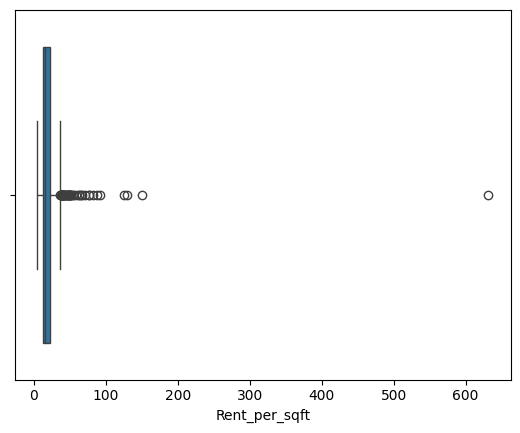

In [12]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])


Text(0.5, 1.0, 'Bangalore')

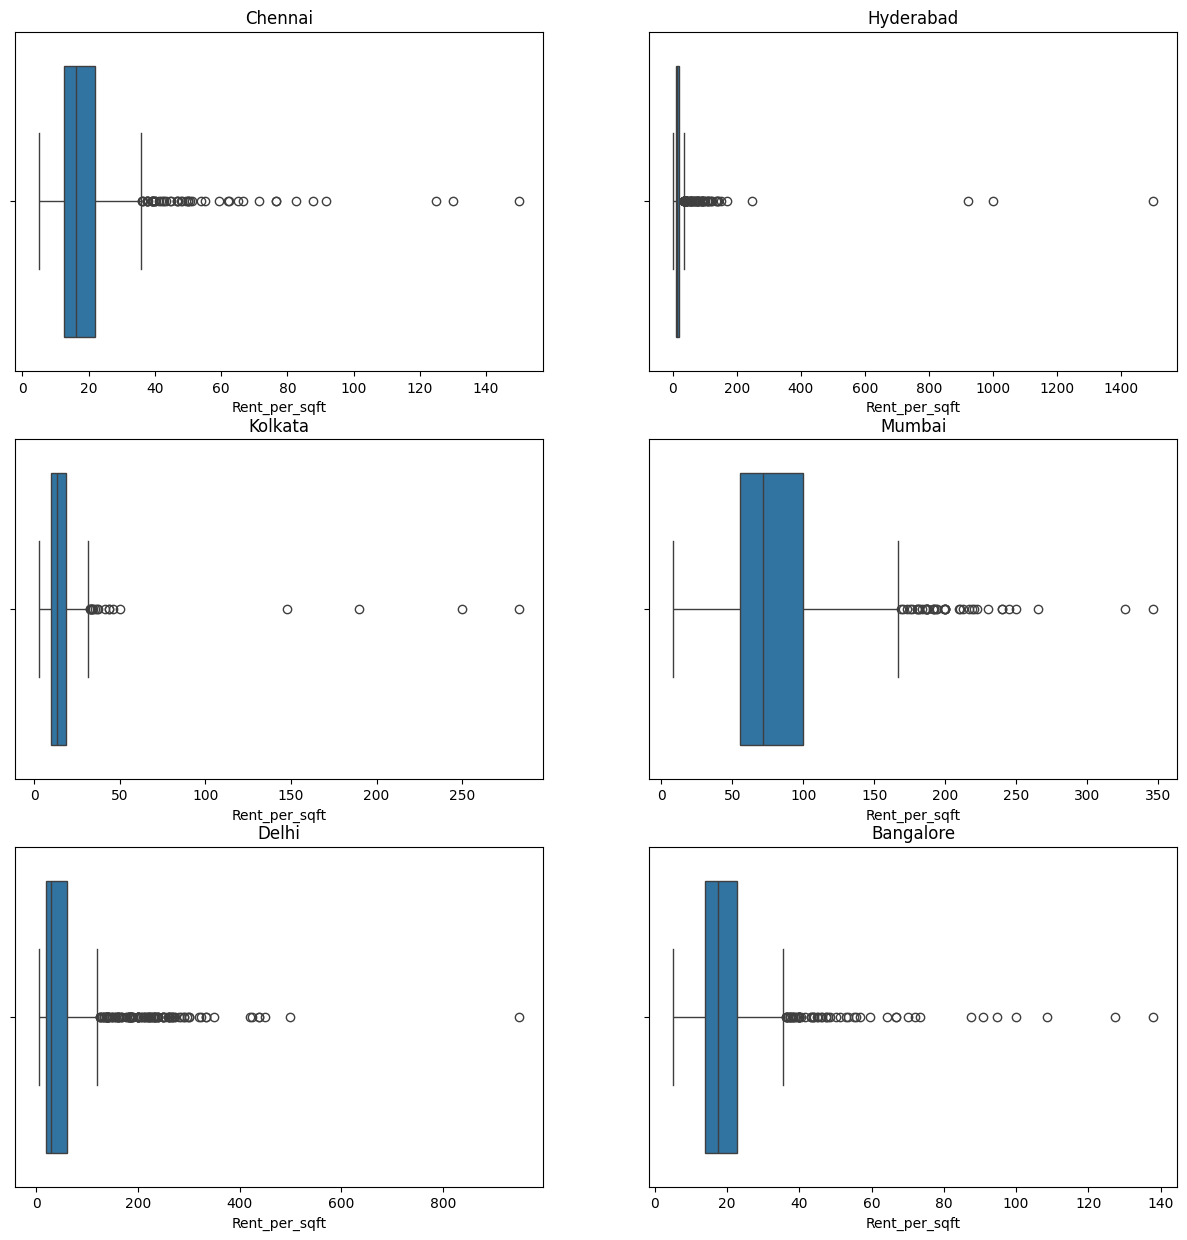

In [13]:
fig ,axes=plt.subplots(3,2,figsize=(15,15))

sns.boxplot(x=whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]<600)]["Rent_per_sqft"] ,ax=axes[0,0])
axes[0,0].set_title("Chennai")
sns.boxplot(x=whole[whole["City"]=="Hyderabad"]["Rent_per_sqft"] ,ax=axes[0,1])
axes[0,1].set_title("Hyderabad")
sns.boxplot(x=whole[whole["City"]=="Kolkata"]["Rent_per_sqft"] ,ax=axes[1,0])
axes[1,0].set_title("Kolkata")
sns.boxplot(x=whole[whole["City"]=="Mumbai"]["Rent_per_sqft"] ,ax=axes[1,1])
axes[1,1].set_title("Mumbai")
sns.boxplot(x=whole[whole["City"]=="Delhi"]["Rent_per_sqft"] ,ax=axes[2,0])
axes[2,0].set_title("Delhi")
sns.boxplot(x=whole[(whole["City"]=="Bangalore") & (whole["Rent_per_sqft"]<1200) ]["Rent_per_sqft"] ,ax=axes[2,1])
axes[2,1].set_title("Bangalore")

In [14]:
whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]>600)]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
3656,2022-07-06,2,600000,950,1 out of 1,Carpet Area,Vettuvankeni,Chennai,Unfurnished,Bachelors,2,Contact Owner,631.578947


In [15]:
whole.iloc[3656]


Posted On               2022-07-06
BHK                              2
Rent                        600000
Size                           950
Floor                   1 out of 1
Area Type              Carpet Area
Area Locality         Vettuvankeni
City                       Chennai
Furnishing Status      Unfurnished
Tenant Preferred         Bachelors
Bathroom                         2
Point of Contact     Contact Owner
Rent_per_sqft           631.578947
Name: 3656, dtype: object

In [16]:
whole.drop(index=3656,inplace=True) #already

<Axes: xlabel='Rent_per_sqft'>

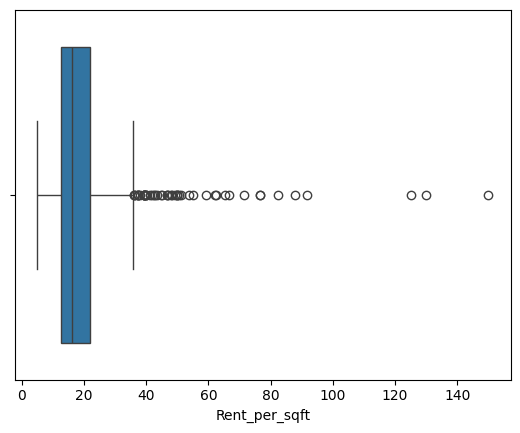

In [17]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])

In [18]:
whole_chennai=whole[whole["City"]=="Chennai"]

In [22]:
with pd.option_context('display.max_rows', None):
    print(whole_chennai["Area Locality"].value_counts())

Area Locality
Velachery                                                  22
Madipakkam                                                 20
Medavakkam                                                 17
Iyyappanthangal                                            17
Sholinganallur                                             16
Vadapalani                                                 15
Chromepet, GST Road                                        15
Ambattur                                                   14
Perungalathur, Chennai Bypass Road                         14
Old Mahabalipuram Road                                     13
Porur                                                      12
Choolaimedu                                                11
Kolathur                                                   11
Valasaravakkam, Arcot Road                                 11
Thiruvanmiyur                                              10
T Nagar                                                 

In [23]:
with pd.option_context('display.max_rows', None):
    print(whole_chennai["Area Locality"].value_counts().head())

Area Locality
Velachery          22
Madipakkam         20
Medavakkam         17
Iyyappanthangal    17
Sholinganallur     16
Name: count, dtype: int64


In [24]:
whole_chennai["Point of Contact"].value_counts()

Point of Contact
Contact Owner    756
Contact Agent    134
Name: count, dtype: int64

Features for this model

In [17]:
#df=whole_chennai[["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]]
#df.describe()
#df.info()
#df.shape

In [25]:
cats = ["Area Type", "Tenant Preferred", "Point of Contact"]   # columns to convert
features=["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]
whole_chennai = whole_chennai.copy()
whole_chennai["Area Type"] = whole_chennai["Area Type"].replace("Built Area", "Super Area")  # merge the 1-row category

X_new = pd.get_dummies(
    whole_chennai[features + cats],   # your 6 numeric columns + the 3 text columns
    columns=cats,            # only encode these 3; numeric columns pass through unchanged
    drop_first=True,         # drop one column per category (the reference)
    dtype=float              # 0.0/1.0 instead of True/False
)
print(X_new.columns.tolist())

['BHK', 'Size', 'Floor', 'Furnishing Status', 'Bathroom', 'Rent', 'Area Type_Super Area', 'Tenant Preferred_Bachelors/Family', 'Tenant Preferred_Family', 'Point of Contact_Contact Owner']


In [26]:
df =X_new.copy()

In [27]:
df

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner
2987,2,1100,1 out of 2,Semi-Furnished,2,15000,1.0,0.0,0.0,1.0
2988,2,1000,Ground out of 1,Semi-Furnished,2,6500,1.0,1.0,0.0,1.0
2989,3,2400,1 out of 3,Semi-Furnished,3,90000,0.0,1.0,0.0,0.0
2990,3,3000,1 out of 1,Furnished,4,200000,1.0,0.0,1.0,0.0
2991,1,650,Ground out of 2,Semi-Furnished,1,15000,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
3873,3,1050,5 out of 10,Semi-Furnished,3,28000,0.0,1.0,0.0,0.0
3874,2,800,5 out of 6,Semi-Furnished,2,10677,1.0,1.0,0.0,1.0
3875,3,1625,8 out of 11,Furnished,3,50000,1.0,1.0,0.0,0.0
3876,3,1535,1 out of 2,Unfurnished,3,32500,1.0,1.0,0.0,0.0


In [28]:
df = df.sample(frac=1, random_state=42)

In [29]:
df["Furnishing Status"] = df["Furnishing Status"].map({"Unfurnished": 0, "Semi-Furnished": 1, "Furnished": 2})
df.head()

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner
3267,2,650,2 out of 2,2,2,17500,0.0,1.0,0.0,1.0
3421,3,1300,19 out of 19,2,3,30000,1.0,1.0,0.0,1.0
3026,2,850,Ground out of 2,0,2,12000,1.0,0.0,1.0,1.0
3404,1,500,1 out of 4,0,1,18000,1.0,1.0,0.0,1.0
3572,2,1000,1 out of 2,0,2,18000,1.0,1.0,0.0,1.0


In [30]:
df['Total_Floors']=df["Floor"].str.extract(r"out of\s*(\d+)")[0].astype(float)

In [31]:
df['Floor_no.']=df["Floor"].str.extract(r"^(\d+)")

In [32]:
df["Floor_no."].value_counts()

Floor_no.
1     321
2     164
3      59
4      30
9      13
5      11
7      10
8       7
10      6
15      6
11      6
6       5
12      3
17      2
19      2
20      1
16      1
25      1
13      1
24      1
28      1
14      1
Name: count, dtype: int64

In [33]:
df.loc[df["Floor"].str.startswith("Ground", na=False),"Floor_no."] = 0

df.loc[df["Floor"].str.startswith("Upper Basement", na=False),"Floor_no."] = -1

df.loc[df["Floor"].str.startswith("Lower Basement", na=False),"Floor_no."] = -2

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 3267 to 3089
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   BHK                                890 non-null    int64  
 1   Size                               890 non-null    int64  
 2   Floor                              890 non-null    object 
 3   Furnishing Status                  890 non-null    int64  
 4   Bathroom                           890 non-null    int64  
 5   Rent                               890 non-null    int64  
 6   Area Type_Super Area               890 non-null    float64
 7   Tenant Preferred_Bachelors/Family  890 non-null    float64
 8   Tenant Preferred_Family            890 non-null    float64
 9   Point of Contact_Contact Owner     890 non-null    float64
 10  Total_Floors                       890 non-null    float64
 11  Floor_no.                          890 non-null    object 


In [35]:
df["Floor_no."] = df["Floor_no."].astype(float)

In [36]:
df.drop(columns=["Floor"],inplace=True)

In [37]:
df[df["Floor_no."]==-1].value_counts()

BHK  Size  Furnishing Status  Bathroom  Rent  Area Type_Super Area  Tenant Preferred_Bachelors/Family  Tenant Preferred_Family  Point of Contact_Contact Owner  Total_Floors  Floor_no.
1    400   0                  1         8000  0.0                   1.0                                0.0                      1.0                             2.0           -1.0         1
Name: count, dtype: int64

In [38]:
cols = df.columns.tolist()
cols.remove('Rent')
cols.append('Rent')

df = df[cols]
df.head()

,BHK,Size,Furnishing Status,Bathroom,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Total_Floors,Floor_no.,Rent
3267,2,650,2,2,0.0,1.0,0.0,1.0,2.0,2.0,17500
3421,3,1300,2,3,1.0,1.0,0.0,1.0,19.0,19.0,30000
3026,2,850,0,2,1.0,0.0,1.0,1.0,2.0,0.0,12000
3404,1,500,0,1,1.0,1.0,0.0,1.0,4.0,1.0,18000
3572,2,1000,0,2,1.0,1.0,0.0,1.0,2.0,1.0,18000


<Axes: >

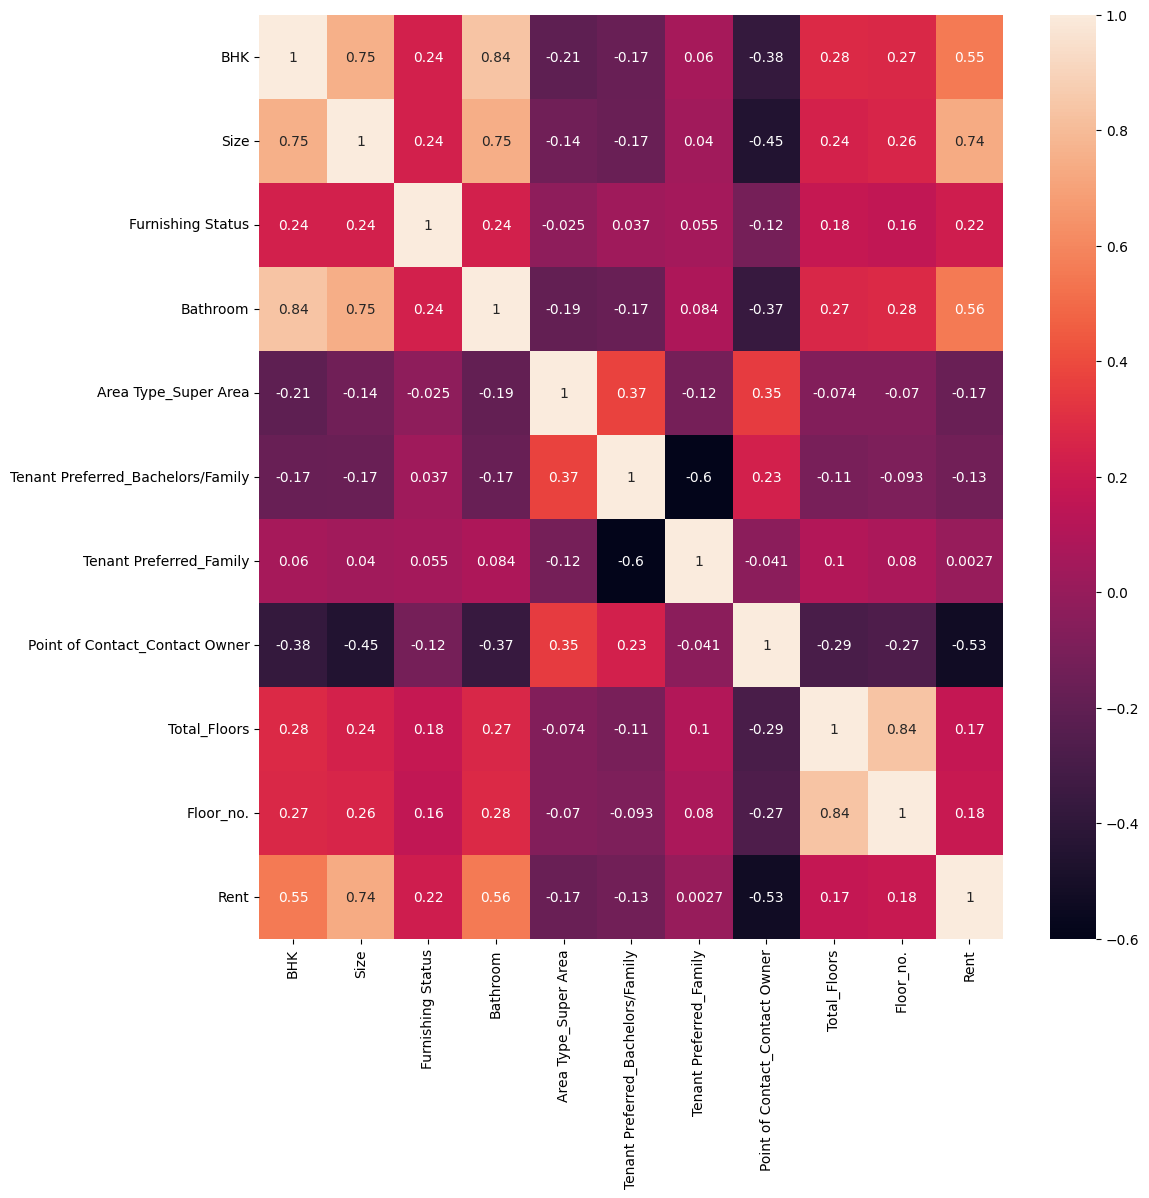

In [39]:
plt.figure(figsize=(12,12))
sns.heatmap(df.corr(numeric_only=True), annot=True)

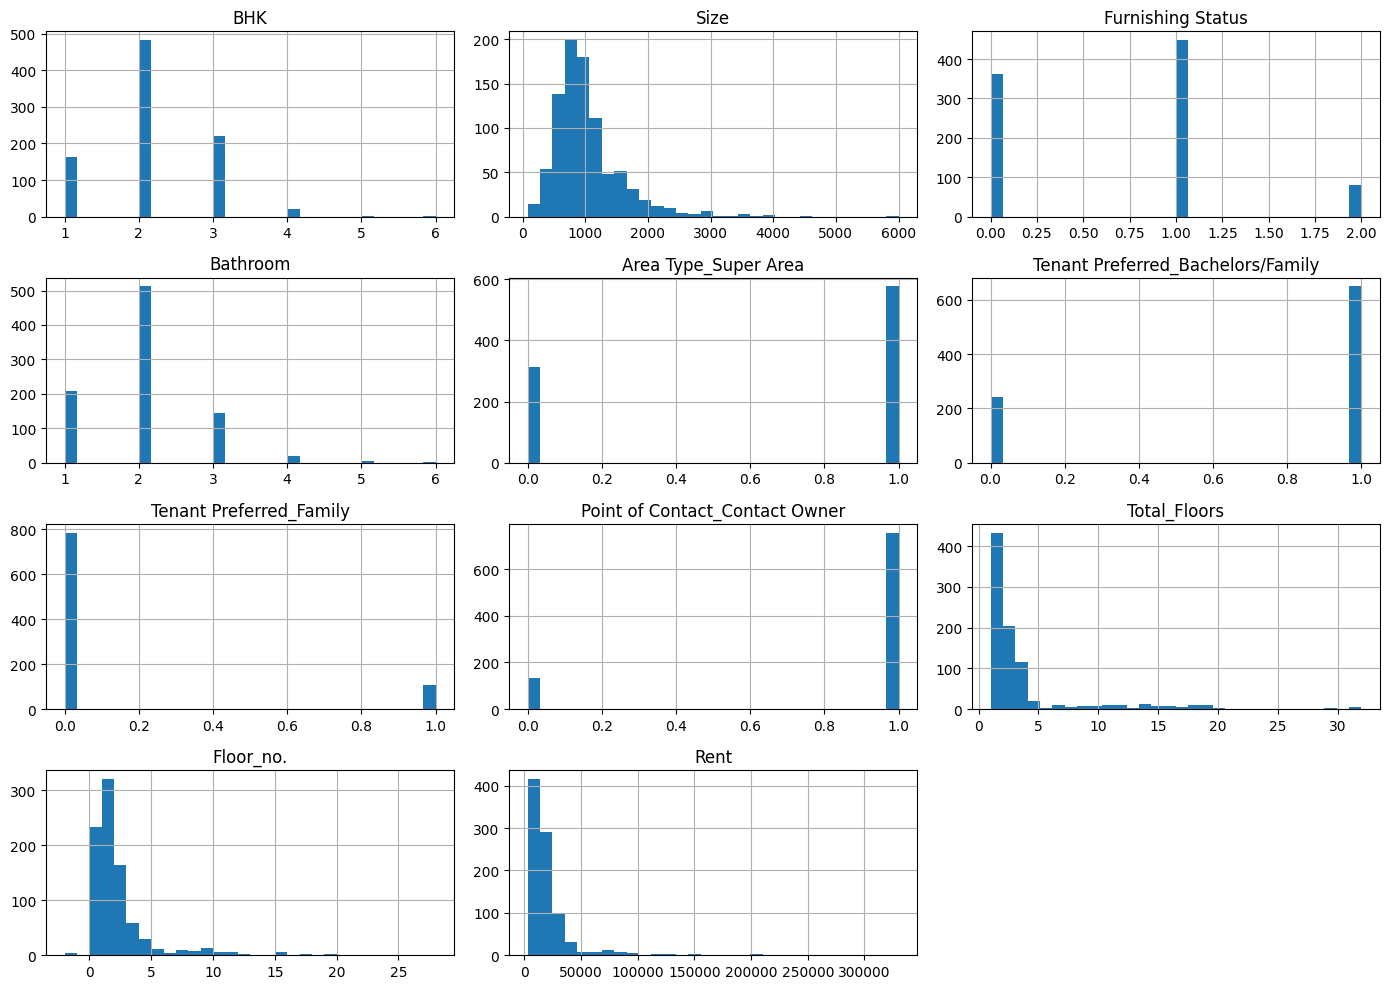

In [40]:
df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()

plt.show()

In [41]:
df_c=df[df["Rent"]<100000]

<Axes: xlabel='Point of Contact_Contact Owner', ylabel='Rent'>

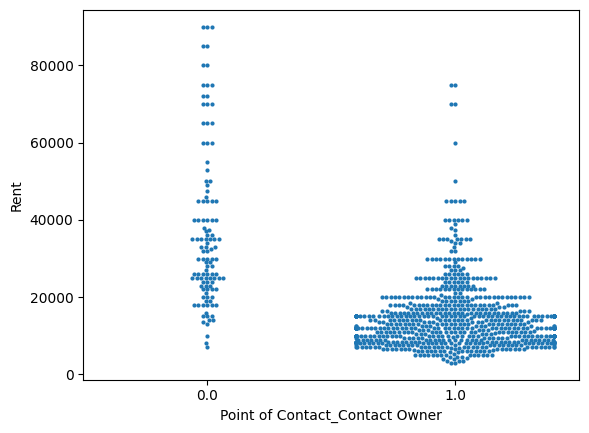

In [42]:
sns.swarmplot(x=df_c["Point of Contact_Contact Owner"],y=df_c["Rent"],size=3)

In [43]:
# --- 2. Log-transform the TARGET ---
#df_c = np.log(df_c["Rent"])          # use np.log1p(y) if Rent can be 0
df

,BHK,Size,Furnishing Status,Bathroom,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Total_Floors,Floor_no.,Rent
3267,2,650,2,2,0.0,1.0,0.0,1.0,2.0,2.0,17500
3421,3,1300,2,3,1.0,1.0,0.0,1.0,19.0,19.0,30000
3026,2,850,0,2,1.0,0.0,1.0,1.0,2.0,0.0,12000
3404,1,500,0,1,1.0,1.0,0.0,1.0,4.0,1.0,18000
3572,2,1000,0,2,1.0,1.0,0.0,1.0,2.0,1.0,18000
...,...,...,...,...,...,...,...,...,...,...,...
3093,2,850,0,2,1.0,1.0,0.0,1.0,3.0,0.0,24000
3257,2,900,2,2,1.0,1.0,0.0,1.0,3.0,2.0,14000
3848,3,1500,0,3,0.0,0.0,0.0,0.0,4.0,2.0,27000
3422,3,1484,1,3,0.0,1.0,0.0,0.0,12.0,9.0,30000


Exploring new features

In [61]:
df_new=df_c.copy()
df_base=df_c.drop(columns=["Area Type_Super Area","Tenant Preferred_Bachelors/Family","Tenant Preferred_Family","Point of Contact_Contact Owner"])
df_fea_en = df_new.copy()
df_fea_en["Size_x_Owner"] = df_fea_en["Size"] * df_fea_en["Point of Contact_Contact Owner"]
drop_cols = [
    'Total_Floors',
    #'Floor_no.',
    'Area Type_Super Area'
]

df_check = df_new.drop(columns=drop_cols)

In [74]:
df_new.head()

,BHK,Size,Furnishing Status,Bathroom,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Total_Floors,Floor_no.,Rent
3267,2,650,2,2,0.0,1.0,0.0,1.0,2.0,2.0,17500
3421,3,1300,2,3,1.0,1.0,0.0,1.0,19.0,19.0,30000
3026,2,850,0,2,1.0,0.0,1.0,1.0,2.0,0.0,12000
3404,1,500,0,1,1.0,1.0,0.0,1.0,4.0,1.0,18000
3572,2,1000,0,2,1.0,1.0,0.0,1.0,2.0,1.0,18000


In [75]:
df_base.head()

,BHK,Size,Furnishing Status,Bathroom,Total_Floors,Floor_no.,Rent
3267,2,650,2,2,2.0,2.0,17500
3421,3,1300,2,3,19.0,19.0,30000
3026,2,850,0,2,2.0,0.0,12000
3404,1,500,0,1,4.0,1.0,18000
3572,2,1000,0,2,2.0,1.0,18000


In [76]:
df_fea_en.head()

,BHK,Size,Furnishing Status,Bathroom,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Total_Floors,Floor_no.,Rent,Size_x_Owner
3267,2,650,2,2,0.0,1.0,0.0,1.0,2.0,2.0,17500,650.0
3421,3,1300,2,3,1.0,1.0,0.0,1.0,19.0,19.0,30000,1300.0
3026,2,850,0,2,1.0,0.0,1.0,1.0,2.0,0.0,12000,850.0
3404,1,500,0,1,1.0,1.0,0.0,1.0,4.0,1.0,18000,500.0
3572,2,1000,0,2,1.0,1.0,0.0,1.0,2.0,1.0,18000,1000.0


In [77]:
df_check.head()

,BHK,Size,Furnishing Status,Bathroom,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner,Floor_no.,Rent
3267,2,650,2,2,1.0,0.0,1.0,2.0,17500
3421,3,1300,2,3,1.0,0.0,1.0,19.0,30000
3026,2,850,0,2,0.0,1.0,1.0,0.0,12000
3404,1,500,0,1,1.0,0.0,1.0,1.0,18000
3572,2,1000,0,2,1.0,0.0,1.0,1.0,18000


In [62]:
def model_features(dataframe):
    # Find the split point

    split = int(0.8 * len(dataframe))

    # Split

    train_df = dataframe.iloc[:split]

    test_df = dataframe.iloc[split:]

    X_train, y_train = train_df .drop("Rent" ,axis=1), train_df["Rent"]
    X_test,  y_test  = test_df.drop("Rent",axis=1), test_df["Rent"]

    return X_train, X_test, y_train, y_test
    


In [88]:
def model_comp(dataframe):
    #df_name="dataframe"
    print(f"linear regression model information for current  dataframe :{dataframe.columns.tolist()} \n") 
    X_train, X_test, y_train, y_test=model_features(dataframe)

# ---------- NEW: log-transform the target ----------
    y_train_log = np.log(y_train)   # CHANGED
    y_test_log  = np.log(y_test)    # CHANGED

# ----------  Z-score scaling (stats from TRAIN only) ----------
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)

    X_train_s = (X_train - mu) / sigma
    X_test_s = (X_test - mu) / sigma

# ----------  Gradient descent ----------
    def gradient_descent(x, y, lr=0.01, epochs=2500):
        n_features = x.shape[1]
        w = np.zeros(n_features)
        b = 0
        m = len(x)

        history = []
        for i in range(epochs):
            y_pred = np.dot(x, w) + b
            error = y_pred - y
            dw = (1 / m) * np.dot(x.T, error)
            db = (1 / m) * np.sum(error)

            w -= lr * dw
            b -= lr * db
            history.append((1 / (2 * m)) * np.sum(error ** 2))
            if i % 200 == 0:
                print(f"epoch {i:4d}  cost = {history[-1]:.6f}")   # CHANGED: cost is now small, need more decimals
        return w, b, history

    w, b, cost_history = gradient_descent(X_train_s, y_train_log)   # CHANGED: train on log(rent)

    print(f"\nLearned weights (scaled space):")
    print(w)
    print(f"Bias (scaled space): {b:.4f}")                          # CHANGED: bias is ~9-10 now

    w_orig = w / sigma
    b_orig = b - np.sum(w * mu / sigma)
    print("In original units (effect on log-rent):")
    print("w =\n", w_orig)
    print("b =", b_orig)

# ----------  Evaluation metrics ----------
    def evaluate(y_true, y_pred):
        mse  = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        mae  = np.mean(np.abs(y_true - y_pred))
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - y_true.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot
        return mse, rmse, mae, r2

# CHANGED: predictions are in log space, convert back with exp
    train_pred_log = np.dot(X_train_s, w) + b
    test_pred_log  = np.dot(X_test_s, w) + b
    train_pred = np.exp(train_pred_log)
    test_pred  = np.exp(test_pred_log)

    print("\n--- Rupee scale  ---")
    for name, yt, yp in [("Train", y_train, train_pred), ("Test", y_test, test_pred)]:
        mse, rmse, mae, r2 = evaluate(yt, yp)
        print(f"{name}: MSE={mse:.1f}  RMSE={rmse:.1f}  MAE={mae:.1f}  R2={r2:.4f}")

    print("\n--- Log scale ---")
    for name, yt, yp in [("Train", y_train_log, train_pred_log), ("Test", y_test_log, test_pred_log)]:
        mse, rmse, mae, r2 = evaluate(yt, yp)
        print(f"{name}: RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")
    print("----------------end----------------\n")
    

In [89]:
model_comp(df_base)
model_comp(df_new)
model_comp(df_fea_en)
model_comp(df_check)


linear regression model information for current  dataframe :['BHK', 'Size', 'Furnishing Status', 'Bathroom', 'Total_Floors', 'Floor_no.', 'Rent'] 

epoch    0  cost = 46.224117
epoch  200  cost = 0.892171
epoch  400  cost = 0.079841
epoch  600  cost = 0.065060
epoch  800  cost = 0.064719
epoch 1000  cost = 0.064683
epoch 1200  cost = 0.064670
epoch 1400  cost = 0.064665
epoch 1600  cost = 0.064663
epoch 1800  cost = 0.064662
epoch 2000  cost = 0.064662
epoch 2200  cost = 0.064661
epoch 2400  cost = 0.064661

Learned weights (scaled space):
[ 0.15913793  0.24478136  0.08019144  0.05852316  0.05923761 -0.00129737]
Bias (scaled space): 9.5965
In original units (effect on log-rent):
w =
 BHK                  0.220663
Size                 0.000512
Furnishing Status    0.128138
Bathroom             0.083373
Total_Floors         0.013259
Floor_no.           -0.000482
dtype: float64
b = 8.323461534844178

--- Rupee scale  ---
Train: MSE=88929181.4  RMSE=9430.2  MAE=5478.5  R2=0.5151
Test: MSE=

In [82]:
#confirming if i have implemented gradent descent correctly

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ---- 1. Fit sklearn on the SAME scaled data and SAME target ----
# (use y_train_log since that's what your GD trained on)
lr = LinearRegression()
lr.fit(X_train_s, y_train_log)

print("Scaled space")
print("sklearn w:", lr.coef_)
print("your    w:", w)
print("sklearn b:", lr.intercept_)
print("your    b:", b)

# ---- 2. Original units (the most reliable comparison) ----
lr_raw = LinearRegression()
lr_raw.fit(X_train, y_train_log)          # unscaled features

print("\nOriginal units")
print("sklearn w:", lr_raw.coef_)
print("your    w:", np.asarray(w_orig))
print("sklearn b:", lr_raw.intercept_)
print("your    b:", b_orig)

# ---- 3. Numeric checks ----
print("\nw match (scaled):  ", np.allclose(w, lr.coef_, atol=1e-4))
print("b match (scaled):  ", np.isclose(b, lr.intercept_, atol=1e-4))
print("w match (original):", np.allclose(np.asarray(w_orig), lr_raw.coef_, atol=1e-5))

# ---- 4. Compare metrics ----
sk_train_log = lr.predict(X_train_s)
sk_test_log  = lr.predict(X_test_s)

print("\nLog-scale R2   sklearn: train %.4f  test %.4f" %
      (r2_score(y_train_log, sk_train_log), r2_score(y_test_log, sk_test_log)))
print("Log-scale R2   yours:   train %.4f  test %.4f" %
      (r2_score(y_train_log, train_pred_log), r2_score(y_test_log, test_pred_log)))

sk_test = np.exp(sk_test_log)
print("\nRupee scale (test), sklearn:")
print("RMSE=%.1f  MAE=%.1f  R2=%.4f" % (
    np.sqrt(mean_squared_error(y_test, sk_test)),
    mean_absolute_error(y_test, sk_test),
    r2_score(y_test, sk_test)))

# ---- 5. Max prediction difference ----
print("\nMax |your pred - sklearn pred| (log space):",
      np.max(np.abs(test_pred_log - sk_test_log)))

Scaled space
sklearn w: [ 0.15288265  0.20399321  0.0809054   0.05662619 -0.00558076 -0.02520637
 -0.00888836 -0.15432009  0.02250459 -0.00412958]
your    w: [ 0.15235435  0.20390563  0.08092784  0.05723272 -0.00559034 -0.02523661
 -0.00892922 -0.15431937  0.02259644 -0.00422804]
sklearn b: 9.596510678452896
your    b: 9.596510678335381

Original units
sklearn w: [ 2.11989642e-01  4.26482724e-04  1.29279316e-01  8.06705613e-02
 -1.16837472e-02 -5.63310411e-02 -2.75331873e-02 -4.44998103e-01
  5.03722009e-03 -1.53264933e-03]
your    w: [ 2.11257088e-01  4.26299620e-04  1.29315183e-01  8.15346317e-02
 -1.17038061e-02 -5.63986383e-02 -2.76597628e-02 -4.44996003e-01
  5.05777852e-03 -1.56919191e-03]
sklearn b: 8.899771907369756
your    b: 8.899833184542558

w match (scaled):   False
b match (scaled):   True
w match (original): False

Log-scale R2   sklearn: train 0.6969  test 0.6697
Log-scale R2   yours:   train 0.6969  test 0.6697

Rupee scale (test), sklearn:
RMSE=6811.3  MAE=4369.9  R2=

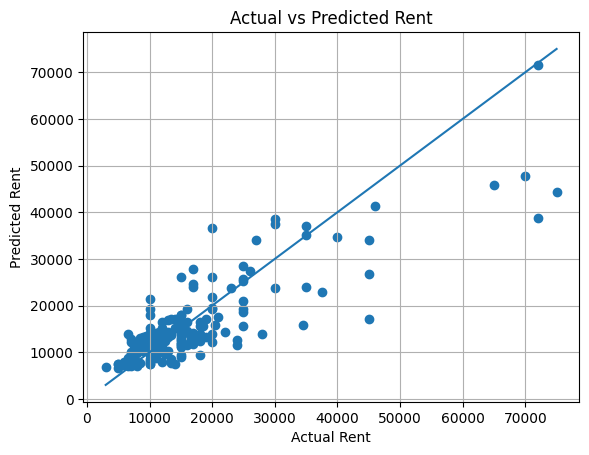

In [84]:
plt.scatter(y_test, test_pred)

minimum = min(y_test.min(), test_pred.min())
maximum = max(y_test.max(), test_pred.max())

plt.plot([minimum, maximum], [minimum, maximum])

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual vs Predicted Rent")
plt.grid()
plt.show()

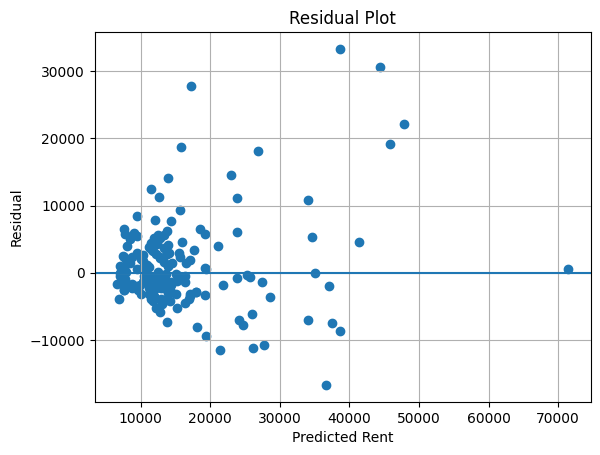

In [85]:
residuals = y_test - test_pred
plt.scatter(test_pred, residuals)

plt.axhline(0)

plt.xlabel("Predicted Rent")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid()
plt.show()

1> compare to see am i doing correct via sciket  #done
2> one hot encoding or target encoding on other columns
3> log on size
4> Benchmark with a tree model. Fit GradientBoostingRegressor or RandomForestRegressor